# Stock Risk Report
Parameterized report for one ticker, run with papermill. Returns, volatility, Sharpe and drawdown use the adjusted close and daily log returns.

In [1]:
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"

In [2]:
# Parameters
ticker = "AAPL"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "data/data.db"


In [3]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.collections import LineCollection
import scrapbook as sb

conn = sqlite3.connect(db_path)
query = """
SELECT ts, open, high, low, close, adj_close, volume
FROM ohlc_hw_cleaned
WHERE ticker = ? AND ts >= ? AND ts <= ?
ORDER BY ts
"""
data = pd.read_sql_query(query, conn, params=(ticker, start_date, end_date))
data["ts"] = pd.to_datetime(data["ts"])
data = data.set_index("ts")

print(f"{ticker} from {start_date} to {end_date}: {len(data)} trading days")
if len(data) < 21:
    raise ValueError(f"{ticker}: only {len(data)} prices in the period, at least 21 are needed for 20 returns")
print("Actual first date:", data.index[0].date(), "| Actual last date:", data.index[-1].date())

AAPL from 2024-06-01 to 2024-11-30: 97 trading days
Actual first date: 2024-06-03 | Actual last date: 2024-10-18


In [4]:
data.head()

,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,192.90,194.99,192.52,194.03,193.81,50080539
2024-06-04,194.64,195.32,193.03,194.35,194.13,47471445
2024-06-05,195.40,196.90,194.87,195.87,195.64,54156785
2024-06-06,195.69,196.50,194.17,194.48,194.26,41181753
2024-06-07,194.65,196.94,194.14,196.89,196.66,53103912


In [5]:
data.tail()

,open,high,low,close,adj_close,volume
ts,,,,,,
2024-10-14,228.70,231.73,228.60,231.30,231.30,39882100
2024-10-15,233.61,237.49,232.37,233.85,233.85,64751400
2024-10-16,231.60,232.12,229.84,231.78,231.78,34082240
2024-10-17,233.43,233.85,230.52,232.15,232.15,32993810
2024-10-18,236.18,236.18,234.01,235.00,235.00,45441281


In [6]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns"""
    return np.log(prices / prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility"""
    return returns.rolling(window).std() * np.sqrt(252)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return per-date drawdown from the running price peak."""
    running_max = prices.cummax()
    return (prices - running_max) / running_max


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate annualized Sharpe ratio"""
    returns = returns.dropna()
    if len(returns) < 2 or returns.std() == 0:
        return np.nan
    return (returns.mean() * 252 - risk_free_rate) / (returns.std() * np.sqrt(252))

In [7]:
prices = data["adj_close"]
returns = calculate_returns(prices)
volatility = calculate_volatility(returns)
drawdown = calculate_max_drawdown(prices)
sharpe = calculate_sharpe_ratio(returns)
ma50 = prices.rolling(50).mean()

print("Number of returns:", returns.count())
print("Mean rolling volatility:", round(volatility.mean(), 4))
print("Sharpe ratio:", round(sharpe, 4))
print("Maximum drawdown:", round(drawdown.min(), 4))
if ma50.isna().all():
    print("Less than 50 prices: the 50-day moving average is not available")

Number of returns: 96
Mean rolling volatility: 0.2408
Sharpe ratio: 1.9087
Maximum drawdown: -0.1175


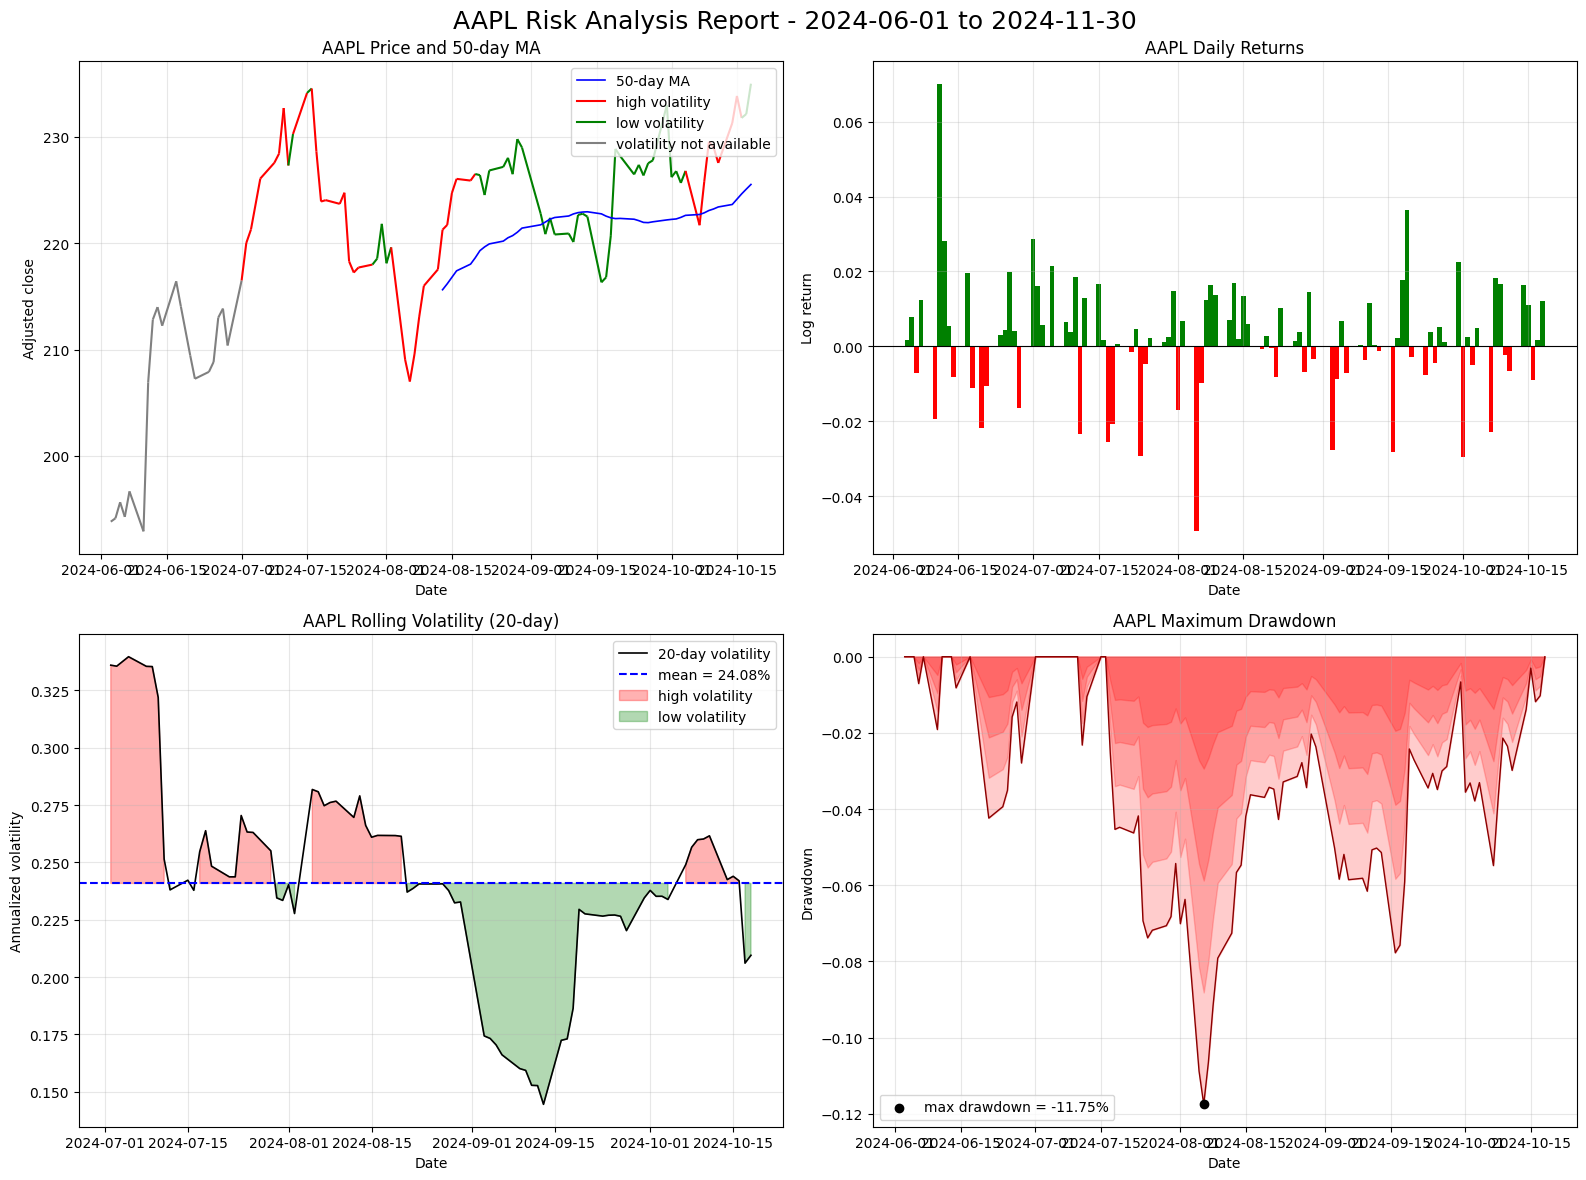

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle(f"{ticker} Risk Analysis Report - {start_date} to {end_date}", fontsize=18)
mean_vol = volatility.mean()

# top left: price colored by volatility
ax = axes[0, 0]
x = mdates.date2num(prices.index)
points = np.column_stack([x, prices.values])
segments = np.stack([points[:-1], points[1:]], axis=1)
colors = []
for v in volatility.values[1:]:
    if np.isnan(v):
        colors.append("gray")
    elif v > mean_vol:
        colors.append("red")
    else:
        colors.append("green")
ax.add_collection(LineCollection(segments, colors=colors, linewidth=1.5))
ax.plot(ma50.index, ma50, color="blue", linewidth=1.2, label="50-day MA")
ax.plot([], [], color="red", label="high volatility")
ax.plot([], [], color="green", label="low volatility")
ax.plot([], [], color="gray", label="volatility not available")
ax.autoscale()
ax.set_title(f"{ticker} Price and 50-day MA")
ax.set_xlabel("Date")
ax.set_ylabel("Adjusted close")
ax.legend()

# top right: daily returns
ax = axes[0, 1]
bar_colors = np.where(returns > 0, "green", "red")
ax.bar(returns.index, returns, color=bar_colors, width=1)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title(f"{ticker} Daily Returns")
ax.set_xlabel("Date")
ax.set_ylabel("Log return")

# bottom left: rolling volatility
ax = axes[1, 0]
ax.plot(volatility.index, volatility, color="black", linewidth=1.2, label="20-day volatility")
ax.axhline(mean_vol, color="blue", linestyle="--", label=f"mean = {mean_vol:.2%}")
ax.fill_between(volatility.index, volatility, mean_vol, where=volatility > mean_vol, color="red", alpha=0.3, label="high volatility")
ax.fill_between(volatility.index, volatility, mean_vol, where=volatility < mean_vol, color="green", alpha=0.3, label="low volatility")
ax.set_title(f"{ticker} Rolling Volatility (20-day)")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized volatility")
ax.legend()

# bottom right: drawdown
ax = axes[1, 1]
for k in [1.0, 0.75, 0.5, 0.25]:
    ax.fill_between(drawdown.index, drawdown * k, 0, color="red", alpha=0.2)
ax.plot(drawdown.index, drawdown, color="darkred", linewidth=1)
ax.scatter(drawdown.idxmin(), drawdown.min(), color="black", zorder=5, label=f"max drawdown = {drawdown.min():.2%}")
ax.set_title(f"{ticker} Maximum Drawdown")
ax.set_xlabel("Date")
ax.set_ylabel("Drawdown")
ax.legend()

for ax in axes.flatten():
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [9]:
r = returns.dropna()
n = len(r)
up = r[r > 0]
down = r[r < 0]

total_return = prices.iloc[-1] / prices.iloc[0] - 1
annual_return = np.exp(r.sum() * 252 / n) - 1
annual_vol = r.std() * np.sqrt(252)

def pct(x, sign=True):
    if pd.isna(x):
        return "N/A"
    return f"{x:+.2%}" if sign else f"{x:.2%}"

summary = pd.DataFrame({
    "Metric": ["Total Return", "Annualized Return", "Annualized Volatility", "Sharpe Ratio",
               "Maximum Drawdown", "Best Day", "Worst Day", "Positive Days",
               "Average Up Day", "Average Down Day"],
    "Value": [pct(total_return), pct(annual_return), pct(annual_vol, False),
              "N/A" if pd.isna(sharpe) else f"{sharpe:.2f}",
              pct(drawdown.min()), pct(r.max()), pct(r.min()), pct((r > 0).sum() / n, False),
              pct(up.mean() if len(up) > 0 else np.nan), pct(down.mean() if len(down) > 0 else np.nan)],
})
summary

,Metric,Value
0,Total Return,+21.25%
1,Annualized Return,+65.84%
2,Annualized Volatility,25.45%
3,Sharpe Ratio,1.91
4,Maximum Drawdown,-11.75%
5,Best Day,+7.01%
6,Worst Day,-4.94%
7,Positive Days,62.50%
8,Average Up Day,+1.09%
9,Average Down Day,-1.28%


In [10]:
sb.glue("ticker", ticker)
sb.glue("first_date", str(data.index[0].date()))
sb.glue("last_date", str(data.index[-1].date()))
sb.glue("avg_daily_return", float(r.mean()))
sb.glue("avg_volatility", float(volatility.mean()))
sb.glue("max_drawdown", float(drawdown.min()))
sb.glue("sharpe_ratio", float(sharpe))
sb.glue("total_return", float(total_return))